<a href="https://colab.research.google.com/github/maramgueye/datascience_with_python/blob/main/Final_Assessment_Gueye_Maram_studentID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Firstly, let's make the relavant import

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Python exercise: Perfect numbers
Definition: A perfect number is a positive integer that is equal to the sum of its proper divisors (excluding the
number itself). For example:

• 6 is a perfect number because its divisors (excluding 6) are 1, 2, and 3, and 1 + 2 + 3 = 6.

• 28 is a perfect number because its divisors (excluding 28) are 1, 2, 4, 7, and 14, and 1 + 2 + 4 + 7 + 14 = 28.

1. Write a Python function is_perfect_number(n) that checks whether a given integer n is a perfect number.
The function should return True if n is a perfect number and False otherwise.
Example:
1 print(is_perfect_number(6)) # Output: True
2 print(is_perfect_number(28)) # Output: True
3 print(is_perfect_number(12)) # Output: False
Describe and summarize the dataset
Dataset 1: Customer invoices
The data_invoices.xlsx dataset contains information about customer invoices. It has the following
columns:
• id_invoice: unique identifier for each invoice.
• amount: monetary value of each invoice
• age customer: age of the customer associated with each invoice.
• items bought: number of items purchased in each invoice.
• debit card: binary indicator representing whether a debit card was used for the purchase.
– 1 indicates a debit card was used.
– 0 indicates a debit card was not used.

In [ ]:
def is_perfect_number(n):
    '''Test if n is a perfect number'''
    #we will firstly take the divisor of the number n excluding n itselves
    div=[]
    for i in range (1, n):
        if n%i==0:
            div.append(i)
    #then we are going to do the sum of the divisor and verify if the result is equal to our number n
    div=np.array(div)
    if div.sum()==n:
        return True
    else:
        return False

Let's run tests with the example given and other non perfect number

In [ ]:
#test
test_lst=[6, 7, 12,28]
for n in test_lst:
    if is_perfect_number(n):
        print (f'{n} is a perfect number')
    else :
        print(f'{n} is not a perfect number')

6 is a perfect number
7 is not a perfect number
12 is not a perfect number
28 is a perfect number


# Describe and summarize the dataset

### 1. Load the data_invoices.xlsx dataset and compute the following descriptive statistics for all continuous variables:
   
(a) Mean

(b) Median

(c) Variance

(d) Standard deviation

(e) Minimum and maximum values

(f) First and third quartiles

La cellule suivant est a execute uniquement si le fichier est lu sur google collab, sinon passe au cellule suivant

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving data_invoices.xlsx to data_invoices.xlsx


In [ ]:
data=pd.read_excel('data_invoices.xlsx', sheet_name='data_invoices')

data.head(7)

,id_invoice,amount,age customer,items bought,debit card
0,1,163.5,43,7,0
1,2,138.8,39,5,0
2,3,175.9,48,7,1
3,4,157.5,45,11,1
4,5,600.0,43,2,0
5,6,132.8,32,5,0
6,7,165.7,42,3,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_invoice    2000 non-null   int64  
 1   amount        2000 non-null   float64
 2   age customer  2000 non-null   int64  
 3   items bought  2000 non-null   int64  
 4   debit card    2000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 78.3 KB


In [ ]:
data.isnull().sum()

,0
id_invoice,0
amount,0
age customer,0
items bought,0
debit card,0


In [ ]:
data.shape

(2000, 5)

We can see that their is no missing values in our dataset

In [ ]:
data.describe(include='all')


,id_invoice,amount,age customer,items bought,debit card
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1000.500000,154.153150,40.072000,8.513500,0.702500
std,577.494589,30.487148,5.052483,4.743635,0.457273
min,1.000000,20.000000,24.000000,0.000000,0.000000
25%,500.750000,134.975000,37.000000,5.000000,0.000000
50%,1000.500000,154.750000,40.000000,8.000000,1.000000
75%,1500.250000,172.525000,43.000000,12.000000,1.000000
max,2000.000000,600.000000,58.000000,32.000000,1.000000


In [ ]:
print(f'      The variances are: \n{data.var()}')

      The variances are: 
id_invoice      333500.000000
amount             929.466183
age customer        25.527580
items bought        22.502069
debit card           0.209098
dtype: float64


### 2. For the categorical variables, count the occurrences of each unique value.
It is only the column debit card that hav categorical variables with 0 representing 'No' and 1 representing 'Yes'

In [ ]:
counts = data['debit card'].value_counts()
counts

,count
debit card,
1,1405
0,595


In [ ]:
# let's take the percentage of the occurence each of the categorical variables
counts = data['debit card'].value_counts(normalize=True)*100
counts

,proportion
debit card,
1,70.25
0,29.75


We can see that there is a majority of payment by debit card with a percentage of 70.25% and only 29.75% that did not pay by card

### 3. Choose the most appropriate visuals to display the distribution of each continuous variable. Justify your choice.

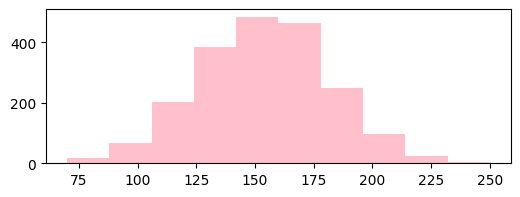

In [ ]:
plt.figure(figsize=(6,2))
plt.hist(data['amount'], range=(70, 250),color='pink')
plt.show()

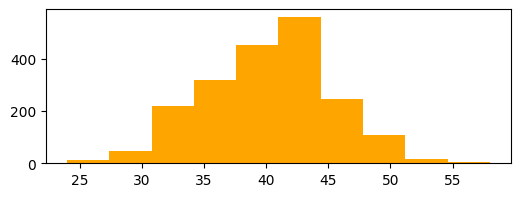

In [ ]:
plt.figure(figsize=(6,2))
plt.hist(data['age customer'], color='orange')
plt.show()

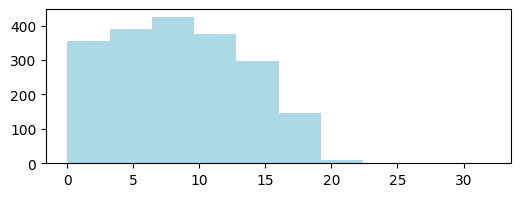

In [ ]:
plt.figure(figsize=(6,2))
plt.hist(data['items bought'], color='lightblue')
plt.show()

### We have 3 plots, we can put them in the same subplot to see all three of them at the same tiem

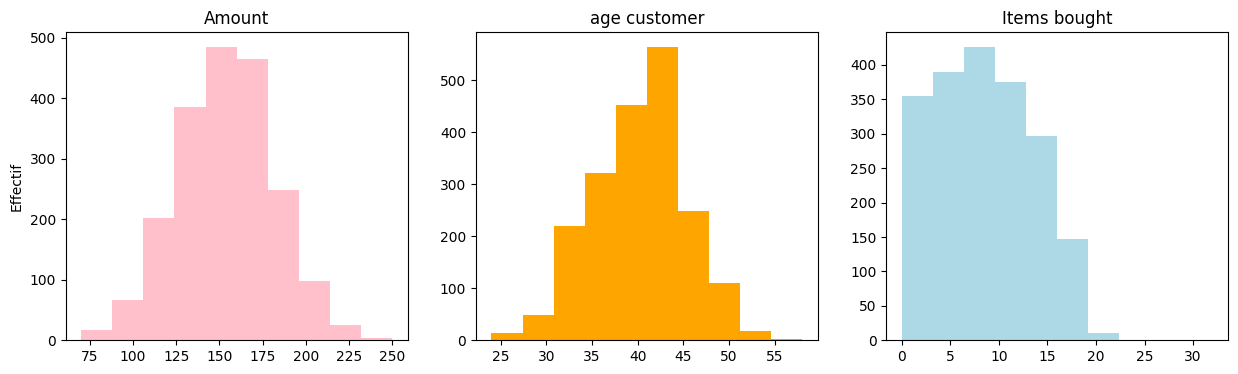

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# amount
ax[0].hist(data['amount'], range=(70, 250), color='pink')
ax[0].set_title('Amount')
ax[0].set_ylabel('Effectif')
# age customer
ax[1].hist(data['age customer'], color='orange')
ax[1].set_title('age customer')
# items bought
ax[2].hist(data['items bought'], color='lightblue')
ax[2].set_title('Items bought')

#plt.tight_layout()
plt.show()

### 4. Choose the most appropriate visuals to display the frequency of each value for categorical variables. Justify your choice.

In [ ]:
counts.values

array([1405,  595])

In [ ]:
counts = data['debit card'].value_counts()
names = counts.index
val=counts.values
plt.bar(counts.index, counts.values, color='lightgreen')
plt.title('Frequency of debit card')
plt.show()

NameError: name 'data' is not defined

### 5. Compute the correlation between the column amount and age customer, as well as between amount and items bought.

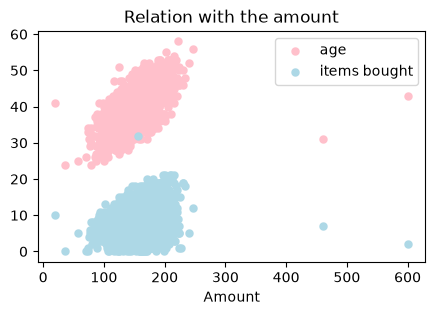

In [ ]:
plt.figure(figsize=(5,3))
plt.scatter(data['amount'], data['age customer'], color='pink', label= 'age', linewidths=0.05)
plt.scatter(data['amount'], data['items bought'], color='lightblue', label= 'items bought', linewidths=0.05)
plt.legend()
plt.xlabel('Amount')
plt.title("Relation with the amount")
plt.show()

In [ ]:
data[['amount', 'age customer']].corr()

,amount,age customer
amount,1.000000,0.615239
age customer,0.615239,1.000000


In [ ]:
data[['amount', 'items bought']].corr()

,amount,items bought
amount,1.000000,0.234581
items bought,0.234581,1.000000


### 6. Interpret the correlation results.

### 7. Choose the most appropriate visualization to summarize the distribution of the amounts paid by clients who used a debit card and those who did not. Justify your choice

# Linear Regression
1. Build a linear regression model where the dependent variable is amount, and the independent variables are
age customer, items bought and credit card.

- (a) Report the coefficients and intercept of the model.



In [ ]:
data.head(10)

,id_invoice,amount,age customer,items bought,debit card
0,1,163.5,43,7,0
1,2,138.8,39,5,0
2,3,175.9,48,7,1
3,4,157.5,45,11,1
4,5,600.0,43,2,0
5,6,132.8,32,5,0
6,7,165.7,42,3,1
7,8,134.1,39,2,1
8,9,174.0,39,1,1
9,10,183.7,41,11,1


In [ ]:
from sklearn.linear_model import LinearRegression
Y = data[['age customer', 'items bought', 'debit card']].values
X = data[['amount']].values
multi_model = LinearRegression().fit(X, Y)
coefficients=multi_model.coef_
intercept = multi_model.intercept_
print(coefficients, intercept)

[[0.10196047]
 [0.03649947]
 [0.00250701]] [24.35447259  2.88699224  0.31603714]


0.15382829492485364


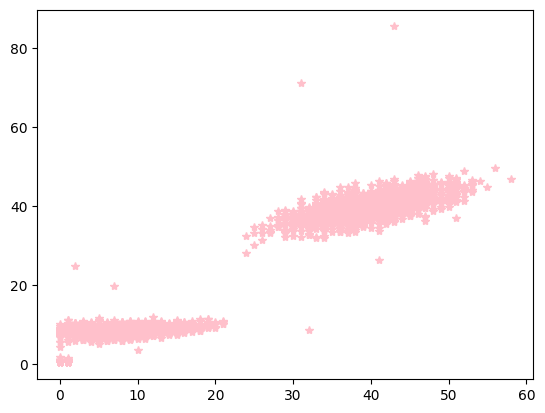

In [ ]:
Y_pred =multi_model.predict(X)
plt.plot(Y, Y_pred, '*', color='pink')
print(multi_model.score(X, Y))

- (b) Interpret the meaning of each coefficient.



- (c) Compute and report the R-squared statistic and explain what it tells you about the model’s fit

In [ ]:
X_expanded = np.concatenate([X, X**2, X**3], axis=1)
print('R2:',multi_model.score(X_expanded, Y))

ValueError: X has 3 features, but LinearRegression is expecting 1 features as input.

2. Use the model to calculate the Root Mean Square Error (RMSE).
Definition: The Root Mean Square Error (RMSE) measures the average magnitude of the error between
the predicted values and the observed values. It is calculated as:
RM SE =
v
u
u
t 1
n
nX
i=1
(yi − ˆyi)2
where yi are the observed values, ˆyi are the predicted values and n is the number of observations.



3. Interpret the RMSE value and what it indicates about the model’s performance.


# Inference and hypothesis testing
1. Compute 95% confidence intervals for the sample means of age customer and amount.


2. Evaluate the claim: “People who used a debit card paid higher amounts.”. Describe the hypothesis test you
would perform to assess this claim and explain the logic behind your chosen method

# Time series analysis

1. Load the MSFT.csv dataset and create time series plots for the columns Close and Volume.


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving MSFT.csv to MSFT.csv


In [ ]:
data2=pd.read_csv('MSFT.csv')
data2.head(5)

,Date,Open,High,Low,Close,Volume
0,19/07/2023,361.750000,362.459991,352.440002,355.079987,39732900
1,20/07/2023,353.570007,357.970001,345.369995,346.869995,33778400
2,21/07/2023,349.149994,350.299988,339.829987,343.769989,69368900
3,24/07/2023,345.850006,346.920013,342.309998,345.109985,26678100
4,25/07/2023,347.109985,351.890015,345.070007,350.980011,41637700


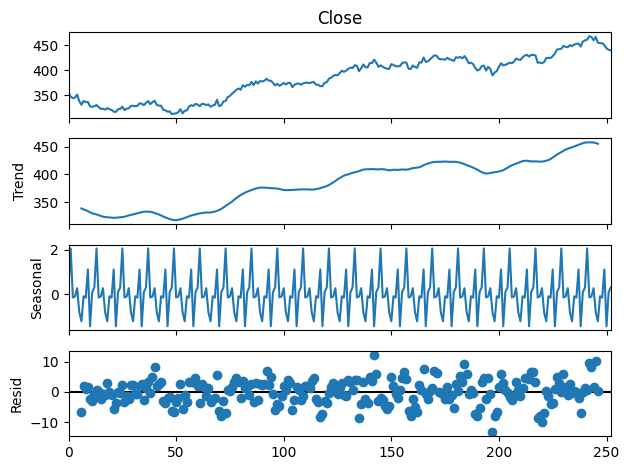

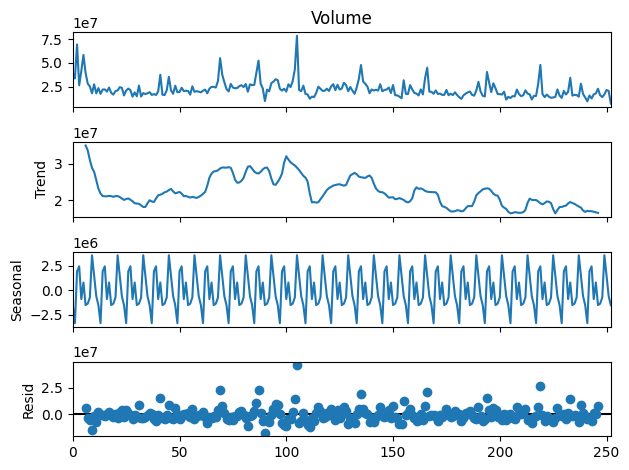

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
result_close = seasonal_decompose(data2['Close'], model='additive', period=12)
result_close.plot()
result_volume = seasonal_decompose(data2['Volume'], model='additive', period=12)
result_volume.plot()
plt.show()

2. Analyze and describe any seasonality and trend observed in both time series.


3. Compute the correlation between Close and Volume. Interpret the result. Does the result align with what
you observe in the plots ?


4. Do you observe any outliers in the two time series ? Are there any points where the trajectory of the time
series shows a noticeable shift or change ?
Definition: An outlier is an extreme value that deviates significantly from other observations in a dataset. It is
an observation that lies an abnormal distance from other values.